# NB12. Modelo final ampliado

**Proyecto:** Análisis de patrones espacio-temporales de accidentes de tránsito en El Salvador
**Etapa:** 2, CRISP-DM Fases 4 y 5 (Modelado y Evaluación)
**Notebook previo:** NB11, Expansión de variables y pruebas de significancia
**Semilla:** 42

---

## Qué hace este notebook

NB11 probó un conjunto de variables candidatas sobre un modelo de Poisson y dejó en
`nb11_especificacion.json` las que superaron sus criterios. Este notebook reentrena el
modelo de frecuencia de NB07 (XGBoost con la exposición como *offset*) con ese conjunto
ampliado y responde tres preguntas:

1. ¿El modelo ampliado predice mejor que el de NB07, y la diferencia es mayor que la que
   produciría el azar?
2. ¿Cuánto aporta cada variable nueva dentro del modelo de árboles?
3. ¿Qué cambia en la calibración por franja horaria y por tipo de territorio?

Se revisa también la sensibilidad de una decisión heredada de NB03, la asignación de
estaciones meteorológicas, con los polígonos oficiales de distrito. La Sección 7 evalúa una
variante más simple del modelo, motivada por lo observado en las secciones 3 a 5.

## Estructura

| Sección | Contenido |
|---|---|
| 1 | Preparación, integridad, reproducción de NB07 y decisiones declaradas |
| 2 | Búsqueda de hiperparámetros con el conjunto ampliado |
| 3 | Comparación en validación 2024 y ablación por variable |
| 4 | Evaluación en el conjunto de prueba |
| 5 | Interpretabilidad y equidad |
| 6 | Sensibilidad de la asignación de estaciones |
| 7 | Variante base + franja (corrección posterior a la observación) |
| 8 | Serialización, resumen y limitaciones |

## Reglas de trabajo

| Regla | Contenido |
|---|---|
| Partición | Train 2022-01-01 a 2024-12-31 / prueba 2025-01-01 a 2026-06-30. No se altera. |
| Selección | Ajuste 2022-2023 / validación 2024, la misma partición interna de NB07. |
| Función objetivo | `RMSE × (1 + λ·\|ln(calibración)\|)`, λ = 1, igual que NB07. |
| Conjunto de prueba | El modelo ampliado se evalúa una sola vez, en la Sección 4: segundo acceso con decisión del proyecto (el primero fue NB07). La variante de la Sección 7 se evalúa una vez más y queda registrada como tercer acceso. |
| Artefactos previos | No se modifican. El modelo nuevo se guarda con otro nombre. |

## 1. Preparación

### 1.1 Entorno e integridad

In [1]:
# NB12 - 1.1 Entorno, rutas e integridad de artefactos previos

import hashlib
import json
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd


def _find_root(marcador: str = "src") -> Path:
    """Sube desde el directorio actual hasta encontrar la raiz del repositorio."""
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / marcador / "config.py").is_file():
            return candidato
    raise RuntimeError(f"No se encontro {marcador}/config.py desde {actual}")


ROOT = _find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as cfg  # noqa: E402

SEED = cfg.SEED
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

ARTEFACTOS_PREVIOS = {
    "matriz_frecuencia_v3": (cfg.PROCESSED_DIR / "matriz_frecuencia_v3.csv.gz", True),
    "nb07_especificacion": (cfg.RESULTS_DIR / "nb07_especificacion.json", True),
    "nb07_metricas": (cfg.RESULTS_DIR / "nb07_metricas.json", True),
    "nb11_especificacion": (cfg.RESULTS_DIR / "nb11_especificacion.json", True),
    "nb11_metricas": (cfg.RESULTS_DIR / "nb11_metricas.json", True),
    "xgb_offset_v2": (cfg.MODELS_DIR / "frecuencia_xgboost_offset_v2.pkl", True),
    "nb08_seccion6": (cfg.RESULTS_DIR / "nb08_seccion6.json", False),
    "siniestros": (cfg.SINIESTROS_FILE, True),
    "estaciones": (cfg.ESTACIONES_FILE, True),
    "distritos_geo": (cfg.DISTRITOS_GEO_FILE, True),
}


def sha256_archivo(ruta: Path, bloque: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


faltantes = [str(r.relative_to(ROOT)) for r, imp in ARTEFACTOS_PREVIOS.values() if imp and not r.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan artefactos imprescindibles:\n  - " + "\n  - ".join(faltantes))

hashes_actuales = {k: sha256_archivo(r) for k, (r, _) in ARTEFACTOS_PREVIOS.items() if r.is_file()}
RUTA_HASHES = cfg.RESULTS_DIR / "nb12_hashes_iniciales.json"
if RUTA_HASHES.is_file():
    base = json.loads(RUTA_HASHES.read_text(encoding="utf-8"))["hashes"]
    alterados = [k for k in base if hashes_actuales.get(k) != base[k]]
    if alterados:
        raise RuntimeError(f"Integridad rota: cambiaron {alterados}")
    estado_integridad = f"verificada ({len(base)} archivos)"
else:
    RUTA_HASHES.write_text(json.dumps({
        "notebook": "NB12_modelo_final_ampliado",
        "generado": datetime.now().isoformat(timespec="seconds"),
        "hashes": hashes_actuales,
    }, indent=2), encoding="utf-8")
    estado_integridad = f"línea base creada ({len(hashes_actuales)} archivos)"

leer = lambda clave: json.loads(ARTEFACTOS_PREVIOS[clave][0].read_text(encoding="utf-8"))
ESPEC_NB07, METRICAS_NB07, ESPEC_NB11 = leer("nb07_especificacion"), leer("nb07_metricas"), leer("nb11_especificacion")
MOD_NB07 = ESPEC_NB07["modelos"]["frecuencia_xgboost_offset_v2.pkl"]

print(f"Integridad          : {estado_integridad}")
print(f"Variables NB07      : {MOD_NB07['columnas']}")
print(f"Variables NB11 (v3) : {ESPEC_NB11['features']}")

Integridad          : verificada (10 archivos)
Variables NB07      : ['es_lluviosa', 'es_finde', 'dia_semana', 'periodo_agostino', 'es_feriado', 'prcp_mensual', 'pct_urbano', 'poblacion_baja']
Variables NB11 (v3) : ['es_lluviosa', 'es_finde', 'dia_semana', 'periodo_agostino', 'es_feriado', 'prcp_mensual', 'pct_urbano', 'poblacion_baja', 'franja_cod', 'crec_parque_12m', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']


### 1.2 Carga de la matriz v3 y particiones

In [2]:
# NB12 - 1.2 Carga de la matriz v3 y particiones

matriz = pd.read_csv(ARTEFACTOS_PREVIOS["matriz_frecuencia_v3"][0], parse_dates=["fecha"])
TARGET, OFFSET = ESPEC_NB11["target"], ESPEC_NB11["offset"]
COL_DISTRITO, COL_FECHA, COL_FRANJA = "distrito_key", "fecha", "franja_horaria"
FEATURES_V2 = list(MOD_NB07["columnas"])
FEATURES_V3 = list(ESPEC_NB11["features"])
NUEVAS = [c for c in FEATURES_V3 if c not in FEATURES_V2]
ORDEN_FRANJAS = sorted(ESPEC_NB11["codificacion_franja"], key=ESPEC_NB11["codificacion_franja"].get)

faltan = [c for c in [TARGET, OFFSET, COL_DISTRITO, COL_FECHA, COL_FRANJA, "split", *FEATURES_V3] if c not in matriz.columns]
if faltan:
    raise RuntimeError(f"Faltan columnas en la matriz v3: {faltan}")


def _rango(texto):
    ini, fin = [p.strip() for p in texto.split(" a ")]
    return pd.Timestamp(ini), pd.Timestamp(fin)


A_INI, A_FIN = _rango(ESPEC_NB07["particion_interna"]["ajuste"])
V_INI, V_FIN = _rango(ESPEC_NB07["particion_interna"]["validacion"])
es_train = matriz["split"].astype(str).str.lower().eq("train")
ajuste = matriz[es_train & matriz[COL_FECHA].between(A_INI, A_FIN)].reset_index(drop=True)
valida = matriz[es_train & matriz[COL_FECHA].between(V_INI, V_FIN)].reset_index(drop=True)
train = matriz[es_train].reset_index(drop=True)
test = matriz[~es_train].reset_index(drop=True)
assert len(ajuste) == ESPEC_NB07["particion_interna"]["filas_ajuste"]
assert len(valida) == ESPEC_NB07["particion_interna"]["filas_validacion"]

# dia_semana: categorias fijadas por train, como en NB07
CAT_DIA = pd.CategoricalDtype(sorted(train["dia_semana"].unique()))

print(f"Ajuste {len(ajuste):,} | validación {len(valida):,} | train {len(train):,} | prueba {len(test):,}")
print(f"Variables nuevas respecto de NB07: {NUEVAS}")

Ajuste 300,760 | validación 150,792 | train 451,552 | prueba 224,952
Variables nuevas respecto de NB07: ['franja_cod', 'crec_parque_12m', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']


### 1.3 Reproducción del modelo de NB07

Se carga el modelo guardado por NB07 y se recalculan sus métricas en el conjunto de prueba.
Deben coincidir con `nb07_metricas.json` hasta el sexto decimal. Esta celda **no cuenta como
evaluación**: reproduce cifras ya publicadas para verificar que la matriz, el entorno y la
carga del modelo son los mismos. Las funciones definidas aquí (predicción con
`base_margin`, métricas y objetivo) se usan en todo el notebook.

In [3]:
# NB12 - 1.3 Funciones comunes y reproduccion de NB07 (control, no evaluacion)

import joblib
import xgboost as xgb
from scipy import stats
from scipy.stats import spearmanr


def preparar_X(df, columnas):
    X = df[columnas].copy()
    if "dia_semana" in X:
        X["dia_semana"] = X["dia_semana"].astype(CAT_DIA).cat.codes
    return X.astype(float)


def tasa_base(y, offset):
    return float(np.sum(y) / np.sum(np.exp(offset)))


def dmatrix(df, columnas, log_tasa, con_etiqueta=True):
    d = xgb.DMatrix(preparar_X(df, columnas), label=df[TARGET].to_numpy() if con_etiqueta else None)
    d.set_base_margin(df[OFFSET].to_numpy() + log_tasa)
    return d


def objetivo_compuesto(rmse, cal, lam=1.0):
    if not np.isfinite(cal) or cal <= 0:
        return float("inf")
    return float(rmse * (1.0 + lam * abs(np.log(cal))))


def evaluar(df, pred):
    y = df[TARGET].to_numpy(); pred = np.asarray(pred, dtype=float)
    g = pd.DataFrame({"d": df[COL_DISTRITO].to_numpy(), "obs": y, "pred": pred}).groupby("d").sum()
    alto = g.nlargest(int(np.ceil(len(g) / 3)), "obs")
    m = {"MAE": float(np.mean(np.abs(y - pred))), "RMSE": float(np.sqrt(np.mean((y - pred) ** 2))),
         "media_predicha": float(pred.mean()), "calibracion": float(pred.mean() / y.mean()),
         "spearman_global": float(spearmanr(g["pred"], g["obs"]).statistic),
         "spearman_tercil_alto": float(spearmanr(alto["pred"], alto["obs"]).statistic)}
    m["objetivo"] = objetivo_compuesto(m["RMSE"], m["calibracion"])
    return m


BOOSTER_NB07 = joblib.load(ARTEFACTOS_PREVIOS["xgb_offset_v2"][0])
LOG_TASA_NB07 = float(MOD_NB07["log_tasa_base"])
pred_test_nb07 = BOOSTER_NB07.predict(dmatrix(test, FEATURES_V2, LOG_TASA_NB07, con_etiqueta=False))
m_rep = evaluar(test, pred_test_nb07)
publicado = METRICAS_NB07["modelos"]["NB07 - XGBoost (exposición offset)"]
dif = {k: abs(m_rep[k] - publicado[k]) for k in ["MAE", "RMSE", "calibracion", "spearman_global", "spearman_tercil_alto"]}
if max(dif.values()) > 1e-6:
    raise RuntimeError(f"No se reproducen las métricas de NB07: {dif}")
print("Reproducción de NB07 en prueba (control de integridad):")
for k, v in dif.items():
    print(f"  {k:<22} {m_rep[k]:.6f}   diferencia {v:.1e}")

Reproducción de NB07 en prueba (control de integridad):
  MAE                    0.200749   diferencia 2.2e-07
  RMSE                   0.412055   diferencia 2.0e-07
  calibracion            0.966979   diferencia 4.6e-08
  spearman_global        0.970777   diferencia 1.9e-07
  spearman_tercil_alto   0.977519   diferencia 4.4e-07


### 1.4 Decisiones declaradas antes de calcular

| Decisión | Contenido |
|---|---|
| **D1** | Espacio de búsqueda, función objetivo, número de ensayos (40), muestreador (TPE, semilla 42), rondas máximas (1,500) y paciencia (50): los mismos de NB07. Así la diferencia entre modelos se debe a las variables y no a un presupuesto de búsqueda distinto. |
| **D2** | La comparación en validación se hace contra un **gemelo de NB07**: los hiperparámetros y rondas de NB07, con sus ocho variables, entrenado en 2022-2023. Comparar contra el modelo guardado, entrenado hasta 2024, mezclaría el efecto de las variables con el de un año más de datos. |
| **D3** | Unidad de las pruebas estadísticas: el **mes**. Las celdas no son independientes (mismo distrito, días consecutivos, franjas del mismo día), así que una prueba sobre 150,792 celdas daría valores p sin sentido. En validación hay 12 meses y en prueba 18. Prueba t pareada sobre el RMSE mensual, con la prueba de Wilcoxon como contraste no paramétrico. |
| **D4** | En prueba se agrega la prueba de Diebold-Mariano sobre la pérdida cuadrática diaria, con varianza de Newey-West (7 rezagos) para la autocorrelación entre días. |
| **D5** | Ablación: se quita cada variable nueva, se reentrena con los mismos hiperparámetros y rondas en 2022-2023 y se mide el cambio del objetivo en validación. El intervalo de 95% se obtiene con bootstrap por bloques de un mes (2,000 remuestreos). |
| **D6** | El modelo ampliado se adopta si en validación mejora el objetivo y la mejora mensual es significativa (p < 0.05 en la prueba t pareada). El Spearman del tercil alto se reporta pero no decide: NB08 mostró que el Spearman por subgrupo depende más del ancho del subgrupo que del modelo. La evaluación en prueba no elige nada; confirma o no lo decidido. |
| **D7** | La sensibilidad de la asignación de estaciones (Sección 6) se reporta sin reentrenar: mide cuántos distritos cambiarían de estación, no su efecto en el modelo. |

In [4]:
# NB12 - 1.4 Registro de decisiones

N_ENSAYOS, MAX_RONDAS, PACIENCIA = 40, 1500, 50
N_BOOT, ALFA, LAGS_NW = 2000, 0.05, 7
cfg.save_metrics({
    "notebook": "NB12_modelo_final_ampliado",
    "generado": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "D1_busqueda": {"ensayos": N_ENSAYOS, "max_rondas": MAX_RONDAS, "paciencia": PACIENCIA,
                    "muestreador": "TPESampler(seed=42)", "espacio": "el de NB07"},
    "D2_referencia_validacion": "gemelo de NB07 (hiperparametros y rondas de NB07, 8 variables) entrenado en 2022-2023",
    "D3_unidad_pruebas": "mes; t pareada sobre RMSE mensual y Wilcoxon",
    "D4_prueba": f"Diebold-Mariano sobre perdida cuadratica diaria, Newey-West {LAGS_NW} rezagos",
    "D5_ablacion": f"bootstrap por bloques mensuales, {N_BOOT} remuestreos",
    "D6_adopcion": f"mejora del objetivo en validacion y p < {ALFA} en t pareada mensual",
    "D7_estaciones": "sensibilidad sin reentrenar",
}, "nb12_decisiones")
print("Decisiones registradas en reports/results/nb12_decisiones.json")

Decisiones registradas en reports/results/nb12_decisiones.json


## 2. Búsqueda de hiperparámetros

Se repite el estudio de Optuna de NB07 con las variables de NB11. El estudio queda guardado
en `reports/results/nb12_optuna.db`: si la ejecución se interrumpe, al volver a correr la
celda continúa desde los ensayos ya completados.

In [5]:
# NB12 - 2.1 Estudio de Optuna con el conjunto ampliado

import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

LOG_TASA_AJUSTE = np.log(tasa_base(ajuste[TARGET], ajuste[OFFSET]))
D_AJU = dmatrix(ajuste, FEATURES_V3, LOG_TASA_AJUSTE)
D_VAL = dmatrix(valida, FEATURES_V3, LOG_TASA_AJUSTE)
y_val = valida[TARGET].to_numpy()


def metrica_objetivo(preds, dmat):
    y = dmat.get_label()
    return "objetivo", objetivo_compuesto(float(np.sqrt(np.mean((y - preds) ** 2))), float(preds.mean() / y.mean()))


def espacio_busqueda(trial):
    return {
        "objective": "count:poisson", "tree_method": "hist", "seed": SEED, "disable_default_eval_metric": 1,
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "eta": trial.suggest_float("eta", 0.02, 0.30, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 200.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 1e2, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1e1, log=True),
        "gamma": trial.suggest_float("gamma", 1e-5, 5.0, log=True),
    }


def entrenar(params, d_aju, d_val=None, rondas=None):
    if rondas is not None:
        return xgb.train(params, d_aju, num_boost_round=rondas, verbose_eval=False)
    return xgb.train(params, d_aju, num_boost_round=MAX_RONDAS, evals=[(d_val, "val")],
                     custom_metric=metrica_objetivo, maximize=False,
                     early_stopping_rounds=PACIENCIA, verbose_eval=False)


def objetivo(trial):
    b = entrenar(espacio_busqueda(trial), D_AJU, D_VAL)
    pred = b.predict(D_VAL, iteration_range=(0, b.best_iteration + 1))
    rmse, cal = float(np.sqrt(np.mean((y_val - pred) ** 2))), float(pred.mean() / y_val.mean())
    trial.set_user_attr("rmse", rmse); trial.set_user_attr("calibracion", cal)
    trial.set_user_attr("n_rondas", int(b.best_iteration + 1))
    return objetivo_compuesto(rmse, cal)


estudio = optuna.create_study(study_name="nb12_xgb_offset_v3", storage=f"sqlite:///{cfg.RESULTS_DIR / 'nb12_optuna.db'}",
                              direction="minimize", sampler=TPESampler(seed=SEED), load_if_exists=True)
hechos = len([t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE])
if N_ENSAYOS - hechos > 0:
    t0 = time.time()
    estudio.optimize(objetivo, n_trials=N_ENSAYOS - hechos, show_progress_bar=False)
    print(f"Ensayos ejecutados: {N_ENSAYOS - hechos} en {time.time() - t0:.0f} s")
mejor = estudio.best_trial
PARAMS = {"objective": "count:poisson", "tree_method": "hist", "seed": SEED, "disable_default_eval_metric": 1, **mejor.params}
N_RONDAS = int(mejor.user_attrs["n_rondas"])
print(f"Mejor objetivo en validación: {mejor.value:.6f} | RMSE {mejor.user_attrs['rmse']:.6f} | "
      f"calibración {mejor.user_attrs['calibracion']:.4f} | rondas {N_RONDAS}")
print("Hiperparámetros:", {k: round(v, 6) if isinstance(v, float) else v for k, v in mejor.params.items()})

Mejor objetivo en validación: 0.371588 | RMSE 0.368524 | calibración 0.9917 | rondas 12
Hiperparámetros: {'max_depth': 7, 'eta': 0.290342, 'min_child_weight': 14.762893, 'subsample': 0.952221, 'colsample_bytree': 0.99577, 'reg_lambda': 0.06883, 'reg_alpha': 0.000409, 'gamma': 0.48002}


## 3. Comparación en validación 2024

### 3.1 Modelo ampliado contra el gemelo de NB07

Los dos modelos se entrenan en 2022-2023 y se evalúan en 2024 (D2). Se reportan las
métricas globales, la comparación mes a mes con sus pruebas y la calibración por franja.

In [6]:
# NB12 - 3.1 Validacion: modelo ampliado vs gemelo de NB07

b_nuevo_aju = entrenar(PARAMS, D_AJU, rondas=N_RONDAS)
pred_val_nuevo = b_nuevo_aju.predict(D_VAL)

params_nb07 = {"objective": "count:poisson", "tree_method": "hist", "seed": SEED, **MOD_NB07["hiperparametros"]}
b_gemelo = entrenar(params_nb07, dmatrix(ajuste, FEATURES_V2, LOG_TASA_AJUSTE), rondas=MOD_NB07["n_rondas"])
pred_val_gemelo = b_gemelo.predict(dmatrix(valida, FEATURES_V2, LOG_TASA_AJUSTE))

comp_val = pd.DataFrame({"gemelo NB07": evaluar(valida, pred_val_gemelo), "ampliado": evaluar(valida, pred_val_nuevo)})
display(comp_val.round(6))


def por_mes(df, pred):
    t = pd.DataFrame({"mes": df[COL_FECHA].dt.to_period("M"), "y": df[TARGET].to_numpy(), "p": np.asarray(pred)})
    return t.groupby("mes").apply(lambda g: pd.Series({
        "RMSE": np.sqrt(np.mean((g.y - g.p) ** 2)), "calibracion": g.p.mean() / g.y.mean()}), include_groups=False)


def prueba_pareada(a, b):
    d = np.asarray(a) - np.asarray(b)
    t = stats.ttest_rel(a, b)
    w = stats.wilcoxon(a, b) if np.any(d != 0) else None
    return {"n_meses": int(len(d)), "dif_media_RMSE": float(d.mean()), "t": float(t.statistic), "p_t": float(t.pvalue),
            "p_wilcoxon": float(w.pvalue) if w is not None else 1.0, "meses_que_mejora": int(np.sum(d > 0))}


mes_val = por_mes(valida, pred_val_gemelo).join(por_mes(valida, pred_val_nuevo), lsuffix="_gemelo", rsuffix="_ampliado")
PRUEBA_VAL = prueba_pareada(mes_val["RMSE_gemelo"], mes_val["RMSE_ampliado"])
display(mes_val.round(5))
print(f"Prueba t pareada (RMSE gemelo - ampliado, {PRUEBA_VAL['n_meses']} meses): "
      f"diferencia media {PRUEBA_VAL['dif_media_RMSE']:.6f}, t = {PRUEBA_VAL['t']:.3f}, p = {PRUEBA_VAL['p_t']:.4g}; "
      f"Wilcoxon p = {PRUEBA_VAL['p_wilcoxon']:.4g}; mejora en {PRUEBA_VAL['meses_que_mejora']} de {PRUEBA_VAL['n_meses']} meses")


def calibracion_por(df, preds, columna, orden=None):
    t = pd.DataFrame({"g": df[columna].to_numpy(), "obs": df[TARGET].to_numpy(), **preds}).groupby("g").sum()
    t = t.reindex(orden) if orden else t
    r = pd.DataFrame({k: t[k] / t["obs"] for k in preds})
    r.index.name = columna
    return r


CAL_FRANJA_VAL = calibracion_por(valida, {"gemelo NB07": pred_val_gemelo, "ampliado": pred_val_nuevo}, COL_FRANJA, ORDEN_FRANJAS)
print("\nCalibración por franja en validación (predicho / observado)")
display(CAL_FRANJA_VAL.round(4))

mejora_obj = comp_val.loc["objetivo", "gemelo NB07"] - comp_val.loc["objetivo", "ampliado"]
ADOPTAR = bool(mejora_obj > 0 and PRUEBA_VAL["p_t"] < ALFA)
print(f"\nDecisión D6: {'se adopta el modelo ampliado' if ADOPTAR else 'NO se adopta el modelo ampliado'} "
      f"(mejora del objetivo {mejora_obj:.6f}, p = {PRUEBA_VAL['p_t']:.4g})")

,gemelo NB07,ampliado
MAE,0.186166,0.179491
RMSE,0.386940,0.368524
media_predicha,0.134601,0.133515
calibracion,0.999789,0.991721
spearman_global,0.980046,0.955043
spearman_tercil_alto,0.960712,0.939982
objetivo,0.387022,0.371588


,RMSE_gemelo,calibracion_gemelo,RMSE_ampliado,calibracion_ampliado
mes,,,,
2024-01,0.36423,1.01959,0.34823,1.05438
2024-02,0.35719,1.00110,0.34294,1.06465
2024-03,0.36126,1.02682,0.34124,1.03395
2024-04,0.37438,0.90217,0.35786,0.96485
2024-05,0.39621,0.85140,0.37817,0.89735
2024-06,0.41366,1.19891,0.38837,1.00948
2024-07,0.39579,0.95048,0.37491,0.97556
2024-08,0.40049,0.97402,0.38326,0.95846
2024-09,0.40954,0.96680,0.39280,0.95045


Prueba t pareada (RMSE gemelo - ampliado, 12 meses): diferencia media 0.018384, t = 21.126, p = 2.968e-10; Wilcoxon p = 0.0004883; mejora en 12 de 12 meses

Calibración por franja en validación (predicho / observado)


,gemelo NB07,ampliado
franja_horaria,,
Madrugada (00-05),3.3427,1.4041
Manana (06-11),0.8502,0.9847
Tarde (12-17),0.6708,0.8886
Noche (18-23),0.9663,1.0290



Decisión D6: se adopta el modelo ampliado (mejora del objetivo 0.015434, p = 2.968e-10)


### 3.2 Ablación por variable

Cada variable nueva se quita del modelo ampliado, se reentrena con los mismos
hiperparámetros y se mide cuánto empeora el objetivo en validación. Un aumento positivo
indica que la variable aporta. El intervalo se calcula remuestreando meses completos (D5).

In [7]:
# NB12 - 3.2 Ablacion por variable con bootstrap por bloques mensuales

meses_val = valida[COL_FECHA].dt.to_period("M").to_numpy()
lista_meses = np.unique(meses_val)
idx_mes = {m: np.where(meses_val == m)[0] for m in lista_meses}
rng = np.random.default_rng(SEED)
muestras_boot = [np.concatenate([idx_mes[m] for m in rng.choice(lista_meses, len(lista_meses), replace=True)])
                 for _ in range(N_BOOT)]


def objetivo_en(idx, pred):
    y, p = y_val[idx], pred[idx]
    return objetivo_compuesto(float(np.sqrt(np.mean((y - p) ** 2))), float(p.mean() / y.mean()))


obj_completo = objetivo_en(np.arange(len(valida)), pred_val_nuevo)
filas = []
for var in NUEVAS:
    cols = [c for c in FEATURES_V3 if c != var]
    b = entrenar(PARAMS, dmatrix(ajuste, cols, LOG_TASA_AJUSTE), rondas=N_RONDAS)
    pred = b.predict(dmatrix(valida, cols, LOG_TASA_AJUSTE))
    delta = objetivo_en(np.arange(len(valida)), pred) - obj_completo
    boot = np.array([objetivo_en(i, pred) - objetivo_en(i, pred_val_nuevo) for i in muestras_boot])
    filas.append({"variable_quitada": var, "aumento_objetivo": delta,
                  "ic95_inf": float(np.percentile(boot, 2.5)), "ic95_sup": float(np.percentile(boot, 97.5))})
ABLACION = pd.DataFrame(filas, columns=["variable_quitada", "aumento_objetivo", "ic95_inf", "ic95_sup"])
ABLACION["aporta"] = ABLACION["ic95_inf"] > 0
if ABLACION.empty:
    print("NB11 no seleccionó variables nuevas: no hay ablación que calcular.")
display(ABLACION.round(6))

,variable_quitada,aumento_objetivo,ic95_inf,ic95_sup,aporta
0,franja_cod,0.019624,0.015124,0.021757,True
1,crec_parque_12m,-0.000574,-0.001756,0.001183,False
2,pct_hogares_auto,0.009250,-0.003509,0.013250,False
3,pct_trabaja_otro_lugar,0.006630,-0.003282,0.010981,False


## 4. Evaluación en el conjunto de prueba

Esta es la única evaluación del modelo ampliado sobre 2025-2026 y queda registrada como
segundo acceso con decisión al conjunto de prueba. El modelo se reentrena con todo el
periodo de train (2022-2024), con el intercepto de exposición recalculado sobre ese
periodo, igual que hizo NB07, y se compara con el modelo guardado de NB07.

In [8]:
# NB12 - 4.1 Evaluacion unica en prueba

LOG_TASA_TRAIN = np.log(tasa_base(train[TARGET], train[OFFSET]))
BOOSTER_V3 = entrenar(PARAMS, dmatrix(train, FEATURES_V3, LOG_TASA_TRAIN), rondas=N_RONDAS)
pred_test_v3 = BOOSTER_V3.predict(dmatrix(test, FEATURES_V3, LOG_TASA_TRAIN, con_etiqueta=False))

comp_test = pd.DataFrame({"NB07": evaluar(test, pred_test_nb07), "ampliado (NB12)": evaluar(test, pred_test_v3)})
display(comp_test.round(6))

mes_test = por_mes(test, pred_test_nb07).join(por_mes(test, pred_test_v3), lsuffix="_NB07", rsuffix="_ampliado")
PRUEBA_TEST = prueba_pareada(mes_test["RMSE_NB07"], mes_test["RMSE_ampliado"])

def diebold_mariano(df, pred_a, pred_b, lags=LAGS_NW):
    """DM sobre la perdida cuadratica diaria; positivo si pred_b tiene menor perdida que pred_a."""
    dias = pd.DataFrame({"dia": df[COL_FECHA].to_numpy(), "ea": (df[TARGET] - pred_a) ** 2,
                         "eb": (df[TARGET] - pred_b) ** 2}).groupby("dia").mean()
    dd = (dias["ea"] - dias["eb"]).to_numpy()
    n, dbar = len(dd), dd.mean()
    gam = [np.mean((dd[k:] - dbar) * (dd[:n - k] - dbar)) for k in range(lags + 1)]
    var = gam[0] + 2 * sum((1 - k / (lags + 1)) * gam[k] for k in range(1, lags + 1))
    dm = float(dbar / np.sqrt(var / n))
    return dm, float(2 * stats.norm.sf(abs(dm))), int(n)


# Diebold-Mariano sobre la perdida cuadratica diaria (D4)
DM, p_dm, n = diebold_mariano(test, pred_test_nb07, pred_test_v3)

print(f"Prueba t pareada ({PRUEBA_TEST['n_meses']} meses): diferencia media de RMSE {PRUEBA_TEST['dif_media_RMSE']:.6f}, "
      f"t = {PRUEBA_TEST['t']:.3f}, p = {PRUEBA_TEST['p_t']:.4g}; Wilcoxon p = {PRUEBA_TEST['p_wilcoxon']:.4g}; "
      f"mejora en {PRUEBA_TEST['meses_que_mejora']} de {PRUEBA_TEST['n_meses']} meses")
print(f"Diebold-Mariano ({n} días, Newey-West {LAGS_NW}): DM = {DM:.3f}, p = {p_dm:.4g}  "
      "(DM positivo: el modelo ampliado tiene menor pérdida)")

CAL_FRANJA_TEST = calibracion_por(test, {"NB07": pred_test_nb07, "ampliado": pred_test_v3}, COL_FRANJA, ORDEN_FRANJAS)
print("\nCalibración por franja en prueba (predicho / observado)")
display(CAL_FRANJA_TEST.round(4))

,NB07,ampliado (NB12)
MAE,0.200749,0.193896
RMSE,0.412055,0.391348
media_predicha,0.145181,0.146619
calibracion,0.966979,0.976557
spearman_global,0.970777,0.945324
spearman_tercil_alto,0.977519,0.939422
objetivo,0.425891,0.400632


Prueba t pareada (18 meses): diferencia media de RMSE 0.020607, t = 28.923, p = 6.725e-16; Wilcoxon p = 7.629e-06; mejora en 18 de 18 meses
Diebold-Mariano (546 días, Newey-West 7): DM = 32.741, p = 4.118e-235  (DM positivo: el modelo ampliado tiene menor pérdida)

Calibración por franja en prueba (predicho / observado)


,NB07,ampliado
franja_horaria,,
Madrugada (00-05),3.3766,1.4049
Manana (06-11),0.8143,0.9648
Tarde (12-17),0.6492,0.8831
Noche (18-23),0.9328,1.0060


In [9]:
# NB12 - 4.2 Registro del uso del conjunto de prueba

usos = []
if ARTEFACTOS_PREVIOS["nb08_seccion6"][0].is_file():
    usos = leer("nb08_seccion6").get("usos_del_test", [])
usos = usos + [{"n": len(usos) + 1, "notebook": "NB12", "celda": "4.1",
                "proposito": "Evaluación del modelo ampliado", "decide": True},
               {"n": len(usos) + 2, "notebook": "NB12", "celda": "1.3",
                "proposito": "Reproducción de métricas publicadas de NB07", "decide": False}]
REGISTRO_TEST = {"usos_del_test": usos, "accesos_decisorios_totales": sum(u["decide"] for u in usos)}
display(pd.DataFrame(usos))
print(f"Accesos con decisión al conjunto de prueba en todo el proyecto: {REGISTRO_TEST['accesos_decisorios_totales']}")

,n,notebook,celda,proposito,decide
0,1,NB07,—,Evaluacion del modelo seleccionado,True
1,2,NB08,1.3,Reproduccion de metricas ya publicadas,False
2,3,NB08,2.1-2.5,Contraste descriptivo junto al diagnostico,False
3,4,NB08,5.2,Contraste de las brechas por subgrupo,False
4,5,NB08,6.2,Confirmacion de las conclusiones,False
5,6,NB12,4.1,Evaluación del modelo ampliado,True
6,7,NB12,1.3,Reproducción de métricas publicadas de NB07,False


Accesos con decisión al conjunto de prueba en todo el proyecto: 2


## 5. Interpretabilidad y equidad

### 5.1 Atribuciones SHAP del modelo ampliado

Mismo procedimiento que NB07: TreeSHAP sobre una muestra de 40,000 celdas del conjunto de
prueba. Las atribuciones están en escala logarítmica, la del predictor lineal del modelo
de Poisson.

,shap_abs_medio
franja_cod,0.33372
pct_hogares_auto,0.17431
pct_urbano,0.15485
pct_trabaja_otro_lugar,0.06529
prcp_mensual,0.03391
crec_parque_12m,0.01998
es_finde,0.01619
poblacion_baja,0.01076
dia_semana,0.00541
es_lluviosa,0.00471


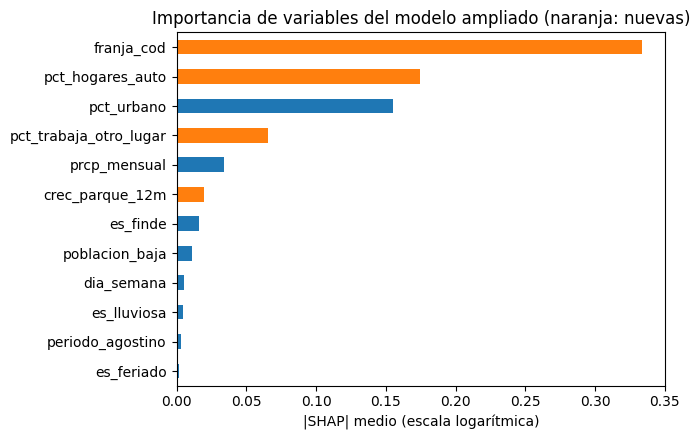

In [10]:
# NB12 - 5.1 SHAP

import shap
import matplotlib.pyplot as plt

muestra = test.sample(n=min(40_000, len(test)), random_state=SEED)
valores = shap.TreeExplainer(BOOSTER_V3).shap_values(preparar_X(muestra, FEATURES_V3))
IMPORTANCIA = (pd.Series(np.abs(valores).mean(axis=0), index=FEATURES_V3)
               .sort_values(ascending=False).rename("shap_abs_medio"))
display(IMPORTANCIA.round(5).to_frame())

fig, ax = plt.subplots(figsize=(7, 4.5))
IMPORTANCIA.iloc[::-1].plot.barh(ax=ax, color=["tab:orange" if v in NUEVAS else "tab:blue" for v in IMPORTANCIA.index[::-1]])
ax.set_xlabel("|SHAP| medio (escala logarítmica)")
ax.set_title("Importancia de variables del modelo ampliado (naranja: nuevas)")
fig.tight_layout()
cfg.save_fig(fig, "nb12_01_shap_importancia")
plt.show()

### 5.2 Calibración por tipo de territorio

NB08 midió una calibración de 0.856 en los 19 distritos más rurales (`pct_urbano < 0.3`)
durante la validación 2024. Se repite la medición con los dos modelos, en validación y en
prueba. En validación, la columna NB07 corresponde al gemelo entrenado en 2022-2023.

In [11]:
# NB12 - 5.2 Calibracion por grupo territorial

def grupo(df):
    return np.where(df["pct_urbano"] < 0.3, "rural (pct_urbano < 0.3)", "resto")


EQUIDAD = pd.concat({
    "validación 2024": calibracion_por(valida.assign(grupo=grupo(valida)),
                                       {"NB07": pred_val_gemelo, "ampliado": pred_val_nuevo}, "grupo"),
    "prueba 2025-2026": calibracion_por(test.assign(grupo=grupo(test)),
                                        {"NB07": pred_test_nb07, "ampliado": pred_test_v3}, "grupo"),
})
display(EQUIDAD.round(4))
print(f"Distritos rurales: {matriz.loc[matriz['pct_urbano'] < 0.3, COL_DISTRITO].nunique()}")

NB07  ampliado
                 grupo                                     
validación 2024  resto                     1.0023    0.9882
                 rural (pct_urbano < 0.3)  0.8591    1.1874
prueba 2025-2026 resto                     0.9686    0.9725
                 rural (pct_urbano < 0.3)  0.8762    1.2035

Distritos rurales: 19


## 6. Sensibilidad de la asignación de estaciones

NB03 asignó a cada distrito la estación meteorológica más cercana a su centroide, y ese
centroide se calculó promediando las coordenadas de sus siniestros, porque no había
polígonos oficiales. Con la capa oficial del Censo 2024 se puede calcular el centro
geométrico del territorio y comparar.

Los dos centroides miden cosas distintas. El de siniestros representa el centro de la
actividad vial; el geométrico, el del territorio, que en distritos extensos puede caer en
zonas sin vías. La comparación mide cuánto depende la asignación de esa elección (D7).

In [12]:
# NB12 - 6.1 Centroides de siniestros vs centroides oficiales

siniestros = cfg.load_siniestros()
siniestros["distrito_key"] = siniestros["distrito"].map(cfg.reconciliar_distrito)
siniestros["departamento_key"] = siniestros["departamento"].map(cfg.norm_distrito)
cent_sin = siniestros.groupby(["departamento_key", "distrito_key"]).agg(
    lat_siniestros=("latitud", "mean"), lon_siniestros=("longitud", "mean"), n_siniestros=("latitud", "size")).reset_index()


def centroide(geom):
    """Centroide ponderado por area (coordenadas geograficas; escala de distrito)."""
    polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    A = cx = cy = 0.0
    for poly in polys:
        x, y = np.asarray(poly[0])[:, 0], np.asarray(poly[0])[:, 1]
        c = x[:-1] * y[1:] - x[1:] * y[:-1]
        a = c.sum() / 2
        A += a; cx += ((x[:-1] + x[1:]) * c).sum() / 6; cy += ((y[:-1] + y[1:]) * c).sum() / 6
    return cy / A, cx / A


# La capa oficial nombra "Delgado" al distrito que siniestros.csv y la matriz llaman "Ciudad Delgado"
ALIAS_GEO = {"delgado": "ciudad delgado"}
geo = cfg.load_distritos_geo()
cent_of = pd.DataFrame([{"departamento_key": cfg.norm_distrito(f["properties"]["Dep_min"]),
                         "distrito_key": ALIAS_GEO.get(cfg.reconciliar_distrito(f["properties"]["Dis_min"]),
                                                       cfg.reconciliar_distrito(f["properties"]["Dis_min"])),
                         **dict(zip(["lat_oficial", "lon_oficial"], centroide(f["geometry"])))} for f in geo["features"]])
cent = cent_sin.merge(cent_of, on=["departamento_key", "distrito_key"], how="left")
sin_poligono = cent[cent["lat_oficial"].isna()]["distrito_key"].tolist()
cent = cent.dropna(subset=["lat_oficial"])

cat = cfg.load_estaciones().set_index("id")
claves = sorted(matriz["estacion_asignada"].unique())
est = pd.DataFrame([{"clave": k, "lat": float(cat.loc[cfg.CLIMA_A_ESTACION[k], "latitud"]),
                     "lon": float(cat.loc[cfg.CLIMA_A_ESTACION[k], "longitud"])} for k in claves])


def mas_cercana(lat, lon):
    d = (est["lat"].to_numpy()[None, :] - lat[:, None]) ** 2 + (est["lon"].to_numpy()[None, :] - lon[:, None]) ** 2
    return est["clave"].to_numpy()[d.argmin(axis=1)]


cent["estacion_siniestros"] = mas_cercana(cent["lat_siniestros"].to_numpy(), cent["lon_siniestros"].to_numpy())
cent["estacion_oficial"] = mas_cercana(cent["lat_oficial"].to_numpy(), cent["lon_oficial"].to_numpy())
asignada = matriz.groupby("distrito_key")["estacion_asignada"].first()
cent["estacion_nb03"] = cent["distrito_key"].map(asignada)
cent["km_entre_centroides"] = np.hypot((cent["lat_siniestros"] - cent["lat_oficial"]) * 111.0,
                                       (cent["lon_siniestros"] - cent["lon_oficial"]) * 111.0 * np.cos(np.radians(13.7)))

coincide_nb03 = int((cent["estacion_siniestros"] == cent["estacion_nb03"]).sum())
cambian = cent[cent["estacion_oficial"] != cent["estacion_nb03"]].sort_values("n_siniestros", ascending=False)
SENSIBILIDAD = {
    "distritos": int(len(cent)), "sin_poligono": sin_poligono,
    "reproduce_nb03": coincide_nb03,
    "cambiarian_de_estacion": int(len(cambian)),
    "pct_siniestros_afectados": float(cambian["n_siniestros"].sum() / cent["n_siniestros"].sum()),
    "km_mediana": float(cent["km_entre_centroides"].median()), "km_max": float(cent["km_entre_centroides"].max()),
}
print(f"Reproducción del método de NB03: {coincide_nb03} de {len(cent)} distritos con la misma estación")
print(f"Distancia entre centroides: mediana {SENSIBILIDAD['km_mediana']:.1f} km, máxima {SENSIBILIDAD['km_max']:.1f} km")
print(f"Con el centroide oficial cambiarían de estación {len(cambian)} distritos "
      f"({SENSIBILIDAD['pct_siniestros_afectados']:.1%} de los siniestros)")
display(cambian[["departamento_key", "distrito_key", "n_siniestros", "estacion_nb03", "estacion_oficial", "km_entre_centroides"]].round(1))

Reproducción del método de NB03: 103 de 103 distritos con la misma estación
Distancia entre centroides: mediana 3.3 km, máxima 39.7 km
Con el centroide oficial cambiarían de estación 6 distritos (3.2% de los siniestros)


,departamento_key,distrito_key,n_siniestros,estacion_nb03,estacion_oficial,km_entre_centroides
90,sonsonate,izalco,1009,SO,SA,5.8
92,sonsonate,nahuizalco,785,SO,SA,4.3
34,la paz,olocuilta,514,IL,PAZ,3.1
80,san vicente,tecoluca,329,IL,PAZ,39.7
76,san vicente,apastepeque,200,IL,PAZ,8.1
22,la libertad,chiltiupan,47,IL,SO,7.4


## 7. Variante base + franja

### 7.1 Por qué se evalúa, y regla de decisión

Las secciones 3 a 5 mostraron que el modelo ampliado mejora el error con alta
significancia, pero dejaron tres señales en contra:

1. El Spearman entre distritos baja respecto de NB07 en validación y en prueba.
2. La calibración rural pasa de subestimar a sobreestimar, con un error mayor.
3. La calibración por franja mejora, pero la madrugada sigue sobreestimada, mientras que el
   modelo de Poisson de NB11 la calibra casi por completo.

La búsqueda de hiperparámetros eligió un modelo de muy pocas rondas, y la ablación solo
encontró un aporte con intervalo que excluye el cero en la franja. Las variables
territoriales nuevas toman un valor distinto por distrito, así que los árboles pueden
usarlas para reconocer distritos individuales, la memorización que NB05 y NB08 ya habían
señalado. La hipótesis es que esas variables explican las tres señales.

Se evalúa por eso una variante con las ocho variables de NB07 más la franja. Es una
**corrección posterior a la observación**: se motiva en resultados ya vistos, y así queda
registrada. Su regla de decisión se fija antes de entrenarla.

| Decisión | Contenido |
|---|---|
| **D8** | La variante se adopta como modelo final si en validación 2024 cumple las tres condiciones: (a) mejora al gemelo de NB07 en el objetivo, con p < 0.05 en la prueba t pareada mensual; (b) su Spearman global no baja más de 0.01 respecto del gemelo; (c) su error de calibración rural, \|calibración − 1\|, es menor que el del modelo ampliado. Si no las cumple, el modelo final es el ampliado. El Spearman del tercil alto se reporta y no decide (NB08). La búsqueda usa el mismo espacio, presupuesto y semilla de la Sección 2. |

In [13]:
# NB12 - 7.1 Registro de la correccion posterior a la observacion (antes de entrenar la variante)

TOL_SPEARMAN = 0.01
cfg.save_metrics({
    "notebook": "NB12_modelo_final_ampliado",
    "generado": datetime.now().isoformat(timespec="seconds"),
    "corregido_post_observacion": True,
    "motivo": ("El modelo ampliado baja el Spearman entre distritos, sobrecorrige la calibracion rural y "
               "deja la franja sin calibrar del todo; la ablacion solo atribuye aporte a la franja."),
    "variante": "8 variables de NB07 + franja_cod",
    "D8_regla": {"a": "mejor objetivo que el gemelo y p < 0.05 en t pareada mensual",
                 "b": f"Spearman global >= gemelo - {TOL_SPEARMAN}",
                 "c": "|calibracion rural - 1| menor que la del modelo ampliado",
                 "si_no_cumple": "modelo final = ampliado"},
}, "nb12_decisiones_correccion")
print("Corrección registrada en reports/results/nb12_decisiones_correccion.json")

Corrección registrada en reports/results/nb12_decisiones_correccion.json


### 7.2 Búsqueda y comparación en validación

In [14]:
# NB12 - 7.2 Variante base + franja: busqueda y validacion

FEATURES_F = [*FEATURES_V2, "franja_cod"]
D_AJU_F = dmatrix(ajuste, FEATURES_F, LOG_TASA_AJUSTE)
D_VAL_F = dmatrix(valida, FEATURES_F, LOG_TASA_AJUSTE)


def objetivo_franja(trial):
    b = entrenar(espacio_busqueda(trial), D_AJU_F, D_VAL_F)
    pred = b.predict(D_VAL_F, iteration_range=(0, b.best_iteration + 1))
    rmse, cal = float(np.sqrt(np.mean((y_val - pred) ** 2))), float(pred.mean() / y_val.mean())
    trial.set_user_attr("rmse", rmse); trial.set_user_attr("calibracion", cal)
    trial.set_user_attr("n_rondas", int(b.best_iteration + 1))
    return objetivo_compuesto(rmse, cal)


estudio_f = optuna.create_study(study_name="nb12_xgb_offset_franja", storage=f"sqlite:///{cfg.RESULTS_DIR / 'nb12_optuna.db'}",
                                direction="minimize", sampler=TPESampler(seed=SEED), load_if_exists=True)
hechos_f = len([t for t in estudio_f.trials if t.state == optuna.trial.TrialState.COMPLETE])
if N_ENSAYOS - hechos_f > 0:
    estudio_f.optimize(objetivo_franja, n_trials=N_ENSAYOS - hechos_f, show_progress_bar=False)
mejor_f = estudio_f.best_trial
PARAMS_F = {"objective": "count:poisson", "tree_method": "hist", "seed": SEED, "disable_default_eval_metric": 1, **mejor_f.params}
N_RONDAS_F = int(mejor_f.user_attrs["n_rondas"])
print(f"Variante: objetivo {mejor_f.value:.6f} | rondas {N_RONDAS_F}")

pred_val_franja = entrenar(PARAMS_F, D_AJU_F, rondas=N_RONDAS_F).predict(D_VAL_F)
comp_val3 = pd.DataFrame({"gemelo NB07": evaluar(valida, pred_val_gemelo), "ampliado": evaluar(valida, pred_val_nuevo),
                          "base + franja": evaluar(valida, pred_val_franja)})
display(comp_val3.round(6))

PRUEBA_VAL_F = prueba_pareada(por_mes(valida, pred_val_gemelo)["RMSE"], por_mes(valida, pred_val_franja)["RMSE"])
print(f"t pareada gemelo vs variante ({PRUEBA_VAL_F['n_meses']} meses): t = {PRUEBA_VAL_F['t']:.3f}, "
      f"p = {PRUEBA_VAL_F['p_t']:.4g}; mejora en {PRUEBA_VAL_F['meses_que_mejora']} de {PRUEBA_VAL_F['n_meses']} meses")

CAL_FRANJA_VAL3 = calibracion_por(valida, {"gemelo NB07": pred_val_gemelo, "ampliado": pred_val_nuevo,
                                           "base + franja": pred_val_franja}, COL_FRANJA, ORDEN_FRANJAS)
CAL_RURAL_VAL3 = calibracion_por(valida.assign(grupo=grupo(valida)), {"gemelo NB07": pred_val_gemelo, "ampliado": pred_val_nuevo,
                                                                     "base + franja": pred_val_franja}, "grupo")
print("\nCalibración por franja y por grupo territorial en validación")
display(pd.concat([CAL_FRANJA_VAL3, CAL_RURAL_VAL3]).round(4))

rural = "rural (pct_urbano < 0.3)"
cond_a = bool(comp_val3.loc["objetivo", "base + franja"] < comp_val3.loc["objetivo", "gemelo NB07"] and PRUEBA_VAL_F["p_t"] < ALFA)
cond_b = bool(comp_val3.loc["spearman_global", "base + franja"] >= comp_val3.loc["spearman_global", "gemelo NB07"] - TOL_SPEARMAN)
cond_c = bool(abs(CAL_RURAL_VAL3.loc[rural, "base + franja"] - 1) < abs(CAL_RURAL_VAL3.loc[rural, "ampliado"] - 1))
ADOPTAR_FRANJA = cond_a and cond_b and cond_c
MODELO_FINAL = "base + franja" if ADOPTAR_FRANJA else ("ampliado" if ADOPTAR else "NB07")
print(f"\nD8: (a) mejora significativa {cond_a} | (b) conserva el ordenamiento {cond_b} | (c) mejor calibración rural {cond_c}")
print(f"Modelo final: {MODELO_FINAL}")

Variante: objetivo 0.368750 | rondas 142


,gemelo NB07,ampliado,base + franja
MAE,0.186166,0.179491,0.177793
RMSE,0.386940,0.368524,0.368447
media_predicha,0.134601,0.133515,0.134518
calibracion,0.999789,0.991721,0.999176
spearman_global,0.980046,0.955043,0.959448
spearman_tercil_alto,0.960712,0.939982,0.926956
objetivo,0.387022,0.371588,0.368750


t pareada gemelo vs variante (12 meses): t = 38.878, p = 3.948e-13; mejora en 12 de 12 meses

Calibración por franja y por grupo territorial en validación


,gemelo NB07,ampliado,base + franja
Madrugada (00-05),3.3427,1.4041,1.0189
Manana (06-11),0.8502,0.9847,1.0077
Tarde (12-17),0.6708,0.8886,0.9661
Noche (18-23),0.9663,1.0290,1.0314
resto,1.0023,0.9882,1.0012
rural (pct_urbano < 0.3),0.8591,1.1874,0.8842



D8: (a) mejora significativa True | (b) conserva el ordenamiento False | (c) mejor calibración rural True
Modelo final: ampliado


### 7.3 Evaluación en prueba de la variante

Tercer acceso con decisión al conjunto de prueba en el proyecto. La variante se reentrena con
todo el periodo de train y se compara con NB07 y con el modelo ampliado.

In [15]:
# NB12 - 7.3 Evaluacion en prueba de la variante (tercer acceso con decision)

BOOSTER_F = entrenar(PARAMS_F, dmatrix(train, FEATURES_F, LOG_TASA_TRAIN), rondas=N_RONDAS_F)
pred_test_franja = BOOSTER_F.predict(dmatrix(test, FEATURES_F, LOG_TASA_TRAIN, con_etiqueta=False))

comp_test3 = pd.DataFrame({"NB07": evaluar(test, pred_test_nb07), "ampliado": evaluar(test, pred_test_v3),
                           "base + franja": evaluar(test, pred_test_franja)})
display(comp_test3.round(6))

PRUEBA_TEST_F = prueba_pareada(por_mes(test, pred_test_nb07)["RMSE"], por_mes(test, pred_test_franja)["RMSE"])
DM_F, p_dm_f, _ = diebold_mariano(test, pred_test_nb07, pred_test_franja)
print(f"NB07 vs variante: t pareada p = {PRUEBA_TEST_F['p_t']:.4g} (mejora en {PRUEBA_TEST_F['meses_que_mejora']} de "
      f"{PRUEBA_TEST_F['n_meses']} meses); Diebold-Mariano = {DM_F:.3f}, p = {p_dm_f:.4g}")

CAL_TEST3 = pd.concat([
    calibracion_por(test, {"NB07": pred_test_nb07, "ampliado": pred_test_v3, "base + franja": pred_test_franja}, COL_FRANJA, ORDEN_FRANJAS),
    calibracion_por(test.assign(grupo=grupo(test)), {"NB07": pred_test_nb07, "ampliado": pred_test_v3,
                                                     "base + franja": pred_test_franja}, "grupo"),
])
print("\nCalibración por franja y por grupo territorial en prueba")
display(CAL_TEST3.round(4))

REGISTRO_TEST["usos_del_test"].append({"n": len(REGISTRO_TEST["usos_del_test"]) + 1, "notebook": "NB12", "celda": "7.3",
                                       "proposito": "Evaluación de la variante base + franja", "decide": True})
REGISTRO_TEST["accesos_decisorios_totales"] = sum(u["decide"] for u in REGISTRO_TEST["usos_del_test"])
print(f"\nAccesos con decisión al conjunto de prueba en todo el proyecto: {REGISTRO_TEST['accesos_decisorios_totales']}")

,NB07,ampliado,base + franja
MAE,0.200749,0.193896,0.190940
RMSE,0.412055,0.391348,0.390075
media_predicha,0.145181,0.146619,0.145174
calibracion,0.966979,0.976557,0.966933
spearman_global,0.970777,0.945324,0.948871
spearman_tercil_alto,0.977519,0.939422,0.939422
objetivo,0.425891,0.400632,0.403191


NB07 vs variante: t pareada p = 3.128e-15 (mejora en 18 de 18 meses); Diebold-Mariano = 29.428, p = 2.386e-190

Calibración por franja y por grupo territorial en prueba


,NB07,ampliado,base + franja
Madrugada (00-05),3.3766,1.4049,1.0270
Manana (06-11),0.8143,0.9648,0.9625
Tarde (12-17),0.6492,0.8831,0.9450
Noche (18-23),0.9328,1.0060,0.9871
resto,0.9686,0.9725,0.9682
rural (pct_urbano < 0.3),0.8762,1.2035,0.8946



Accesos con decisión al conjunto de prueba en todo el proyecto: 3


## 8. Serialización, resumen y limitaciones

### 8.1 Modelos y especificación

Se guardan el modelo ampliado y la variante base + franja, con nombres nuevos, sin
sobrescribir ningún artefacto de NB07. `nb12_especificacion.json` indica cuál es el modelo
final según la regla D8. Igual que en NB07, `log_tasa_base` no forma parte de los objetos
serializados: viaja en la especificación y es obligatorio para predecir.

In [16]:
# NB12 - 8.1 Serializacion

RUTA_MODELO = cfg.MODELS_DIR / "frecuencia_xgboost_offset_v3.pkl"
if RUTA_MODELO.exists():
    raise FileExistsError(f"{RUTA_MODELO.name} ya existe. Ningún artefacto de NB12 sobrescribe uno previo.")
joblib.dump(BOOSTER_V3, RUTA_MODELO, compress=3)
RUTA_MODELO_F = cfg.MODELS_DIR / "frecuencia_xgboost_offset_v3_franja.pkl"
if RUTA_MODELO_F.exists():
    raise FileExistsError(f"{RUTA_MODELO_F.name} ya existe. Ningún artefacto de NB12 sobrescribe uno previo.")
joblib.dump(BOOSTER_F, RUTA_MODELO_F, compress=3)

cfg.save_metrics({
    "notebook": "NB12_modelo_final_ampliado",
    "generado": datetime.now().isoformat(timespec="seconds"),
    "matriz": ARTEFACTOS_PREVIOS["matriz_frecuencia_v3"][0].name,
    "modelo": RUTA_MODELO.name,
    "algoritmo": "XGBoost Booster (objective count:poisson)",
    "columnas": FEATURES_V3,
    "codificacion_dia_semana": "cat.codes con categorias fijadas por train",
    "codificacion_franja": ESPEC_NB11["codificacion_franja"],
    "base_margin": f"{OFFSET} + log_tasa_base",
    "log_tasa_base": float(LOG_TASA_TRAIN),
    "advertencia": "Sin log_tasa_base las predicciones se desvian varios ordenes de magnitud. No esta dentro del objeto.",
    "hiperparametros": mejor.params,
    "n_rondas": N_RONDAS,
    "adoptado": ADOPTAR,
    "modelo_final": MODELO_FINAL,
    "variante_base_franja": {
        "modelo": RUTA_MODELO_F.name,
        "columnas": FEATURES_F,
        "base_margin": f"{OFFSET} + log_tasa_base",
        "log_tasa_base": float(LOG_TASA_TRAIN),
        "hiperparametros": mejor_f.params,
        "n_rondas": N_RONDAS_F,
        "adoptada": ADOPTAR_FRANJA,
    },
}, "nb12_especificacion")

cfg.save_metrics({
    "notebook": "NB12_modelo_final_ampliado",
    "validacion": {"comparacion": comp_val.to_dict(), "prueba_mensual": PRUEBA_VAL,
                   "calibracion_por_franja": CAL_FRANJA_VAL.to_dict(), "adoptado": ADOPTAR},
    "ablacion": ABLACION.to_dict(orient="records"),
    "prueba": {"comparacion": comp_test.to_dict(), "prueba_mensual": PRUEBA_TEST,
               "diebold_mariano": {"DM": DM, "p": p_dm, "dias": int(n), "lags_newey_west": LAGS_NW},
               "calibracion_por_franja": CAL_FRANJA_TEST.to_dict()},
    "registro_test": REGISTRO_TEST,
    "importancia_shap": IMPORTANCIA.to_dict(),
    "equidad": {f"{a} | {b}": v for (a, b), v in EQUIDAD.to_dict(orient="index").items()},
    "sensibilidad_estaciones": SENSIBILIDAD,
    "variante_base_franja": {
        "validacion": {"comparacion": comp_val3.to_dict(), "prueba_mensual": PRUEBA_VAL_F,
                       "calibracion": pd.concat([CAL_FRANJA_VAL3, CAL_RURAL_VAL3]).to_dict(),
                       "D8": {"a": cond_a, "b": cond_b, "c": cond_c}, "adoptada": ADOPTAR_FRANJA},
        "prueba": {"comparacion": comp_test3.to_dict(), "prueba_mensual": PRUEBA_TEST_F,
                   "diebold_mariano": {"DM": DM_F, "p": p_dm_f}, "calibracion": CAL_TEST3.to_dict()},
    },
    "modelo_final": MODELO_FINAL,
}, "nb12_metricas")
print(f"Modelos: {RUTA_MODELO.relative_to(ROOT)} y {RUTA_MODELO_F.relative_to(ROOT)}")
print(f"Modelo final según D8: {MODELO_FINAL}")
print("Especificación y métricas: reports/results/nb12_especificacion.json, nb12_metricas.json")

Modelos: models/frecuencia_xgboost_offset_v3.pkl y models/frecuencia_xgboost_offset_v3_franja.pkl
Modelo final según D8: ampliado
Especificación y métricas: reports/results/nb12_especificacion.json, nb12_metricas.json


In [17]:
# NB12 - 8.2 Integridad al cierre y resumen

cambios = [k for k, (r, _) in ARTEFACTOS_PREVIOS.items() if r.is_file() and sha256_archivo(r) != hashes_actuales[k]]
if cambios:
    raise RuntimeError(f"El notebook modificó artefactos previos: {cambios}")
print(f"Integridad de artefactos previos: verificada ({len(hashes_actuales)} archivos intactos)\n")

print("RESUMEN")
print("-" * 78)
print(f"Variables añadidas a NB07          : {NUEVAS}")
print(f"Validación, objetivo               : gemelo NB07 {comp_val.loc['objetivo', 'gemelo NB07']:.6f} | "
      f"ampliado {comp_val.loc['objetivo', 'ampliado']:.6f}")
print(f"Validación, t pareada mensual      : p = {PRUEBA_VAL['p_t']:.4g}  -> "
      f"el ampliado {'supera' if ADOPTAR else 'no supera'} a NB07 (D6)")
print(f"Prueba, RMSE                       : NB07 {comp_test.loc['RMSE', 'NB07']:.6f} | "
      f"ampliado {comp_test.loc['RMSE', 'ampliado (NB12)']:.6f}")
print(f"Prueba, calibración                : NB07 {comp_test.loc['calibracion', 'NB07']:.4f} | "
      f"ampliado {comp_test.loc['calibracion', 'ampliado (NB12)']:.4f}")
print(f"Prueba, Spearman tercil alto       : NB07 {comp_test.loc['spearman_tercil_alto', 'NB07']:.4f} | "
      f"ampliado {comp_test.loc['spearman_tercil_alto', 'ampliado (NB12)']:.4f}")
print(f"Prueba, t pareada / Diebold-Mariano: p = {PRUEBA_TEST['p_t']:.4g} / p = {p_dm:.4g}")
print(f"Variables cuya ablación empeora    : {ABLACION.loc[ABLACION['aporta'], 'variable_quitada'].tolist()}")
print(f"Estaciones, distritos que cambian  : {SENSIBILIDAD['cambiarian_de_estacion']} "
      f"({SENSIBILIDAD['pct_siniestros_afectados']:.1%} de los siniestros)")
print(f"Variante base + franja, prueba     : RMSE {comp_test3.loc['RMSE', 'base + franja']:.6f} | "
      f"Spearman global {comp_test3.loc['spearman_global', 'base + franja']:.4f} | "
      f"calibración rural {CAL_TEST3.loc['rural (pct_urbano < 0.3)', 'base + franja']:.4f}")
print(f"MODELO FINAL (D8)                  : {MODELO_FINAL}")
print("-" * 78)

Integridad de artefactos previos: verificada (10 archivos intactos)

RESUMEN
------------------------------------------------------------------------------
Variables añadidas a NB07          : ['franja_cod', 'crec_parque_12m', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']
Validación, objetivo               : gemelo NB07 0.387022 | ampliado 0.371588
Validación, t pareada mensual      : p = 2.968e-10  -> el ampliado supera a NB07 (D6)
Prueba, RMSE                       : NB07 0.412055 | ampliado 0.391348
Prueba, calibración                : NB07 0.9670 | ampliado 0.9766
Prueba, Spearman tercil alto       : NB07 0.9775 | ampliado 0.9394
Prueba, t pareada / Diebold-Mariano: p = 6.725e-16 / p = 4.118e-235
Variables cuya ablación empeora    : ['franja_cod']
Estaciones, distritos que cambian  : 6 (3.2% de los siniestros)
Variante base + franja, prueba     : RMSE 0.390075 | Spearman global 0.9489 | calibración rural 0.8946
MODELO FINAL (D8)                  : ampliado
-------------------------

### 8.3 Limitaciones

| Limitación | Implicación |
|---|---|
| La capa de eventos es sintética (NB01) | Las mejoras medidas describen la capacidad del modelo sobre este conjunto. Las variables externas son reales; su efecto sobre la siniestralidad real requiere registros reales para confirmarse. |
| Un solo periodo de prueba | El conjunto de prueba se ha consultado con decisión tres veces en el proyecto (NB07 y dos veces en NB12). Cada consulta adicional reduce su independencia; el registro de usos queda en `nb12_metricas.json`. |
| La variante de la Sección 7 se motivó en resultados ya observados | Su regla se fijó antes de entrenarla y queda registrada como corrección posterior a la observación en `nb12_decisiones_correccion.json`. |
| Reglas del generador del conjunto sintético no documentadas | No se puede determinar si la asociación de las variables territoriales con los siniestros refleja el modo en que se generaron los datos. Se interpretan como asociaciones dentro del conjunto. |
| Pocas unidades para las pruebas | Con 12 meses en validación y 18 en prueba, una diferencia pequeña puede no alcanzar significancia aunque exista. |
| Variables censales estáticas y parque por domicilio del propietario | Heredadas de NB11. |
| Sensibilidad de estaciones sin reentrenar | La Sección 6 dice cuántos distritos cambiarían de estación, no cuánto cambiaría el modelo. |
| `log_tasa_base` fuera del objeto serializado | Igual que en NB07: el `.pkl` y `nb12_especificacion.json` deben viajar juntos. |